# Brain MRI Segmentation Project

**University of Tehran  
Department of Computer Science – Artificial Intelligence**

Dr.Sajedi

Mohammad Jadidi
610300036


## Project Overview

In this project we apply image segmentation techniques to identify and delineate tumor regions in brain MRI images. We use the LGG Segmentation Dataset (3929 TIFF images from 110 patients) and implement a U-Net model with a dynamic threshold post-processing step to improve the segmentation results.


---

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import binary_crossentropy
from tensorflow.keras import backend as K
from skimage.morphology import remove_small_objects
from skimage.filters import threshold_otsu  
from sklearn.model_selection import train_test_split


## 2. Data Loading and Dataset Familiarization

The dataset is stored in a directory structure where each patient (directories starting with 'TCGA') has arount 20 - 27 slices with corresponding masks. We load these images, resize them to 256x256, normalize the pixel values, and convert masks to binary format.



In [4]:
IMG_SIZE = 256
SMALL_REGION_THRESHOLD = 250  

def load_data():
    images, masks = [], []
    image_dir = '/kaggle/input/lgg-mri-segmentation/kaggle_3m'  
    
    for patient_dir in os.listdir(image_dir):
        if not patient_dir.startswith('TCGA'):
            continue
        patient_path = os.path.join(image_dir, patient_dir)
        for i in range(1, 27):
            img_path = os.path.join(patient_path, f'{patient_dir}_{i}.tif')
            mask_path = os.path.join(patient_path, f'{patient_dir}_{i}_mask.tif')
            
            img = cv2.imread(img_path)
            if img is None:
                continue
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0  
            
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None:
                continue
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
            mask = (mask > 0.5).astype(np.float32)  
            mask = np.expand_dims(mask, axis=-1)
            
            images.append(img)
            masks.append(mask)
    
    return np.array(images), np.array(masks)


X, y = load_data()
print("Dataset loaded:", X.shape, y.shape)



Dataset loaded: (2706, 256, 256, 3) (2706, 256, 256, 1)


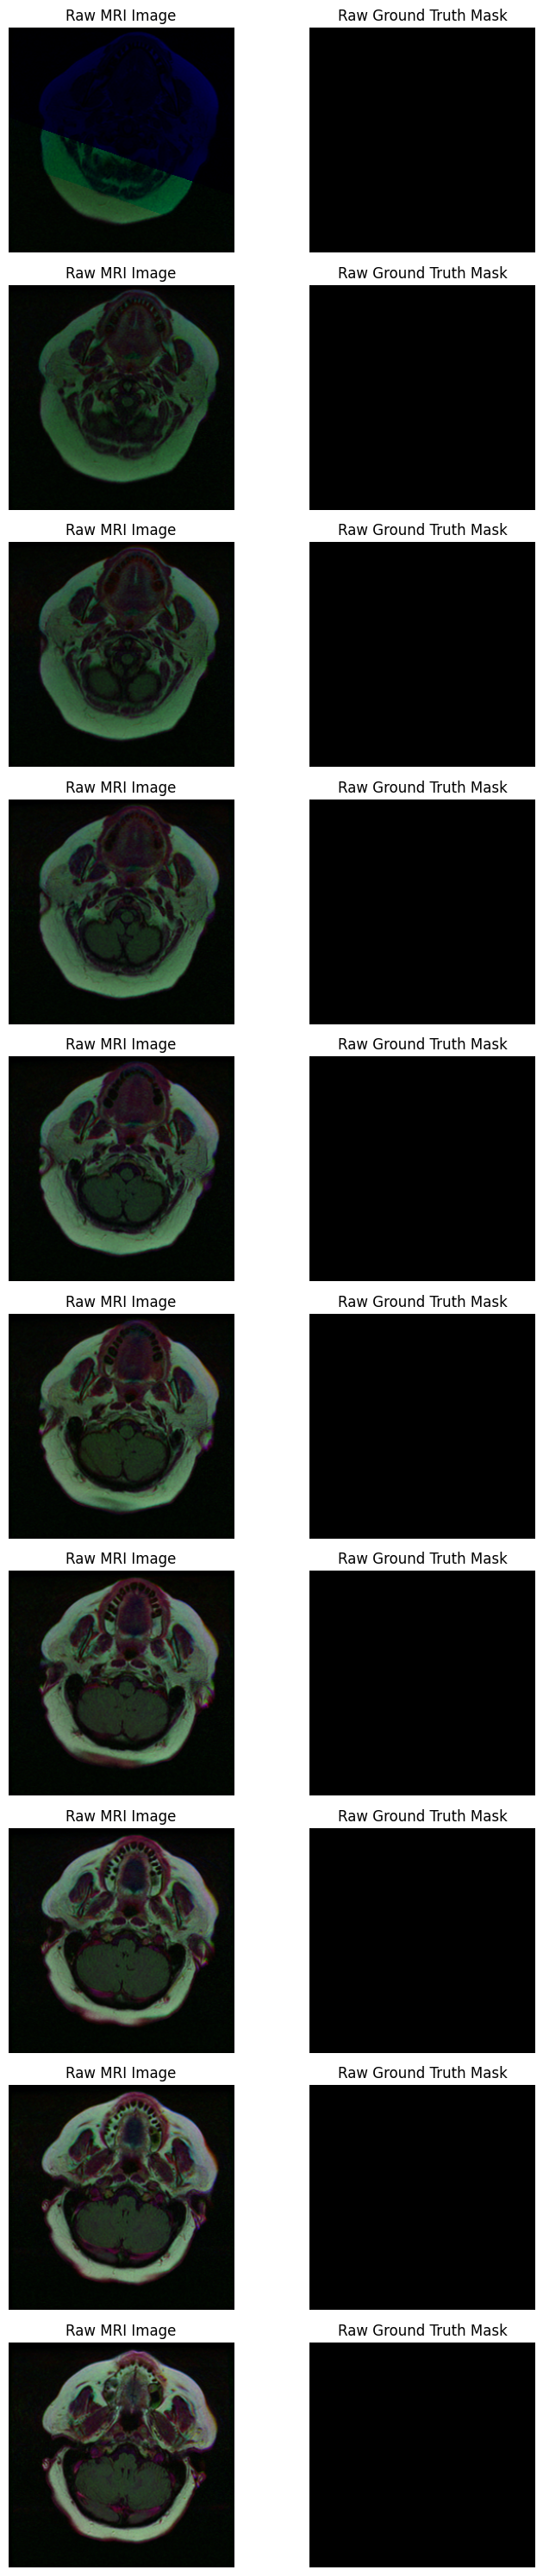

In [5]:
def display_samples(images, masks, num_samples=10, title_prefix="Raw"):
    
    fig, axes = plt.subplots(num_samples, 2, figsize=(8, num_samples * 3))
    for i in range(num_samples):
        axes[i, 0].imshow(images[i])
        axes[i, 0].set_title(f'{title_prefix} MRI Image')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(masks[i].squeeze(), cmap='gray')
        axes[i, 1].set_title(f'{title_prefix} Ground Truth Mask')
        axes[i, 1].axis('off')
    plt.tight_layout()
    plt.show()


display_samples(X, y, num_samples=10, title_prefix="Raw")

## 3. Preprocessing: Data Splitting

We now split the dataset into training (80%), validation (10%), and test (10%) sets. This will allow us to train the model, tune hyperparameters, and finally evaluate the performance on unseen data.


Train set: (2164, 256, 256, 3) (2164, 256, 256, 1)
Validation set: (271, 256, 256, 3) (271, 256, 256, 1)
Test set: (271, 256, 256, 3) (271, 256, 256, 1)


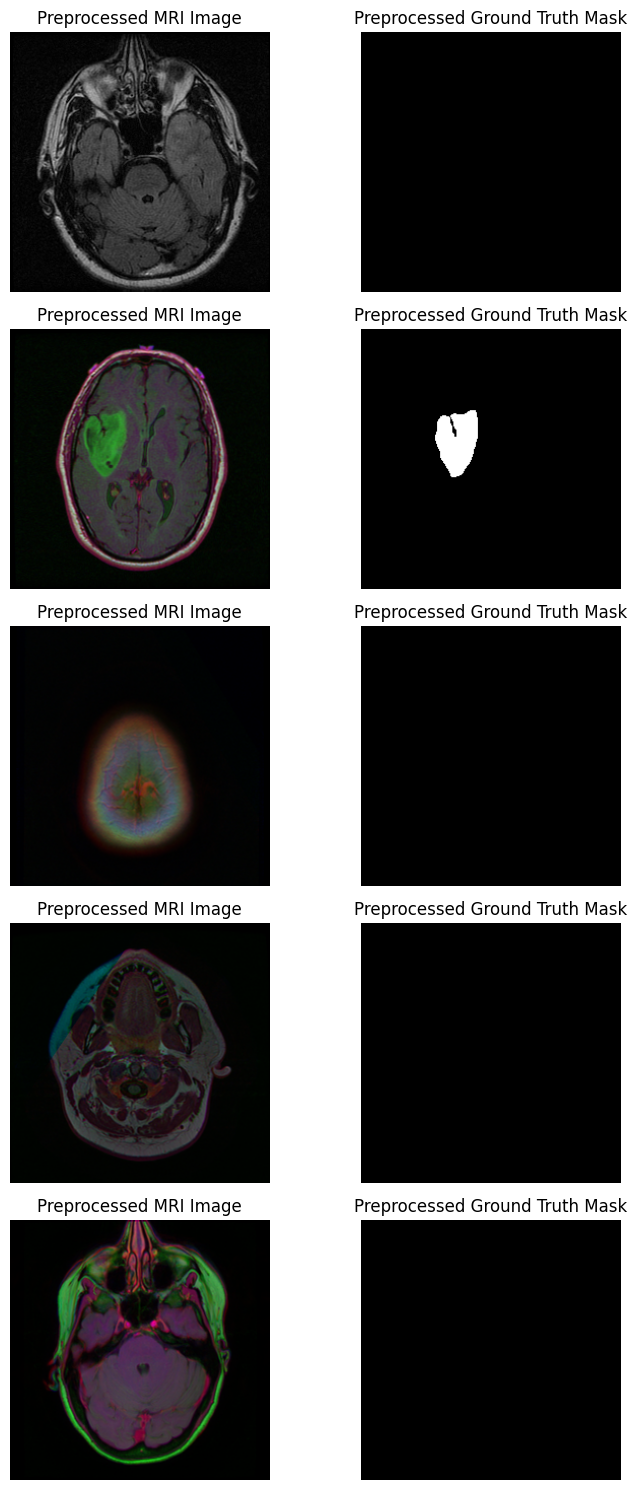

In [6]:

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

display_samples(X_train, y_train, num_samples=5, title_prefix="Preprocessed")


## 4. Model Implementation: U-Net with Dynamic Thresholding and Custom Metrics

We implement a U-Net architecture with the following details:
- **Loss Function:** A combination of Dice loss and binary crossentropy.
- **Metrics:** Accuracy and a custom Intersection over Union (IoU) metric.
- **Dynamic Thresholding:** Post-process predictions using Otsu's method to decide the best threshold per image.

### 4.1 Loss Functions and Metrics

In [7]:
def dice_loss(y_true, y_pred):
    smooth = 1.0
    intersection = tf.reduce_sum(y_true * y_pred)
    return 1 - (2. * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def combined_loss(y_true, y_pred):
    return binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

def iou_metric(y_true, y_pred, smooth=1e-6):
    y_pred_bin = K.cast(y_pred > 0.5, 'float32')
    intersection = K.sum(y_true * y_pred_bin, axis=[1,2,3])
    union = K.sum(y_true, axis=[1,2,3]) + K.sum(y_pred_bin, axis=[1,2,3]) - intersection
    iou = K.mean((intersection + smooth) / (union + smooth), axis=0)
    return iou

### 4.2 U-Net Model Definition

The U-Net model consists of an encoder (downsampling) and decoder (upsampling) path with skip connections. The final layer uses a sigmoid activation to produce a probability map for the segmentation.


In [8]:
def unet_model(input_size=(IMG_SIZE, IMG_SIZE, 3)):
    inputs = Input(input_size)
    
    # Encoder
    c1 = Conv2D(64, (3,3), activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, (3,3), activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2,2))(c1)
    
    c2 = Conv2D(128, (3,3), activation='relu', padding='same')(p1)
    c2 = Conv2D(128, (3,3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2,2))(c2)
    
    c3 = Conv2D(256, (3,3), activation='relu', padding='same')(p2)
    c3 = Conv2D(256, (3,3), activation='relu', padding='same')(c3)
    
    # Decoder
    u4 = Conv2DTranspose(128, (2,2), strides=(2,2), padding='same')(c3)
    u4 = concatenate([u4, c2])
    c4 = Conv2D(128, (3,3), activation='relu', padding='same')(u4)
    c4 = Conv2D(128, (3,3), activation='relu', padding='same')(c4)
    
    u5 = Conv2DTranspose(64, (2,2), strides=(2,2), padding='same')(c4)
    u5 = concatenate([u5, c1])
    c5 = Conv2D(64, (3,3), activation='relu', padding='same')(u5)
    c5 = Conv2D(64, (3,3), activation='relu', padding='same')(c5)
    
    outputs = Conv2D(1, (1,1), activation='sigmoid')(c5)
    
    model = Model(inputs=[inputs], outputs=[outputs])
    return model


seg_model = unet_model()
seg_model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss=combined_loss,
                  metrics=['accuracy', iou_metric])
seg_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 256, 256, 64)   │          1,792 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 256, 256, 64)   │         36,928 │ conv2d[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 128, 128, 64)   │              0 │ conv2d_1[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ conv2d_2[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 64, 64, 128)    │              0 │ conv2d_3[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 64, 64, 256)    │        295,168 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 64, 64, 256)    │        590,080 │ conv2d_4[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose          │ (None, 128, 128, 128)  │        131,200 │ conv2d_5[0][0]         │
│ (Conv2DTranspose)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 128, 128, 256)  │              0 │ conv2d_transpose[0][0… │
│                           │                        │                │ conv2d_3[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_6 (Conv2D)         │ (None, 128, 128, 128)  │        295,040 │ concatenate[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_7 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ conv2d_6[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose_1        │ (None, 256, 256, 64)   │         32,832 │ conv2d_7[0][0]         │
│ (Conv2DTranspose)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate_1             │ (None, 256, 256, 128)  │              0 │ conv2d_transpose_1[0]… │
│ (Concatenate)             │                        │                │ conv2d_1[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_8 (Conv2D)         │ (None, 256, 256, 64)   │         73,792 │ concatenate_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_9 (Conv2D)    

 Total params: 1,862,849 (7.11 MB)

 Trainable params: 1,862,849 (7.11 MB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Training the Model

We train the model for 5 epochs with a batch size of 8. The training history will include loss, accuracy, and IoU which can be used later for analysis.


In [9]:
EPOCHS = 5
BATCH_SIZE = 16

history = seg_model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE)


Epoch 1/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 75s 390ms/step - accuracy: 0.9834 - iou_metric: 0.5876 - loss: 1.3035 - val_accuracy: 0.9886 - val_iou_metric: 0.6096 - val_loss: 0.7778
Epoch 2/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 30s 224ms/step - accuracy: 0.9882 - iou_metric: 0.6187 - loss: 0.7181 - val_accuracy: 0.9871 - val_iou_metric: 0.6584 - val_loss: 0.5791
Epoch 3/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 31s 225ms/step - accuracy: 0.9902 - iou_metric: 0.6808 - loss: 0.5220 - val_accuracy: 0.9889 - val_iou_metric: 0.6647 - val_loss: 0.5569
Epoch 4/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 31s 224ms/step - accuracy: 0.9915 - iou_metric: 0.7005 - loss: 0.5062 - val_accuracy: 0.9897 - val_iou_metric: 0.6285 - val_loss: 0.5246
Epoch 5/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 31s 224ms/step - accuracy: 0.9917 - iou_metric: 0.6883 - loss: 0.4801 - val_accuracy: 0.9911 - val_iou_metric: 0.6993 - val_loss: 0.5027


## 5. Post-Processing and Results Analysis

After training, we post-process the model's predictions to reduce false positives. We apply a dynamic threshold using Otsu's method on each prediction, followed by removal of small isolated regions.


In [10]:
def post_process_mask(mask):
    
    mask = mask.squeeze()  #
    if np.unique(mask).size > 1:
        dynamic_thresh = threshold_otsu(mask)
    else:
        dynamic_thresh = 0.5
    mask_binary = mask > dynamic_thresh
    mask_filtered = remove_small_objects(mask_binary, SMALL_REGION_THRESHOLD)
    return mask_filtered.astype(np.uint8)


### 5.1 Plotting Training History

We now plot the training history to visualize loss, accuracy, and IoU metrics for both training and validation sets.


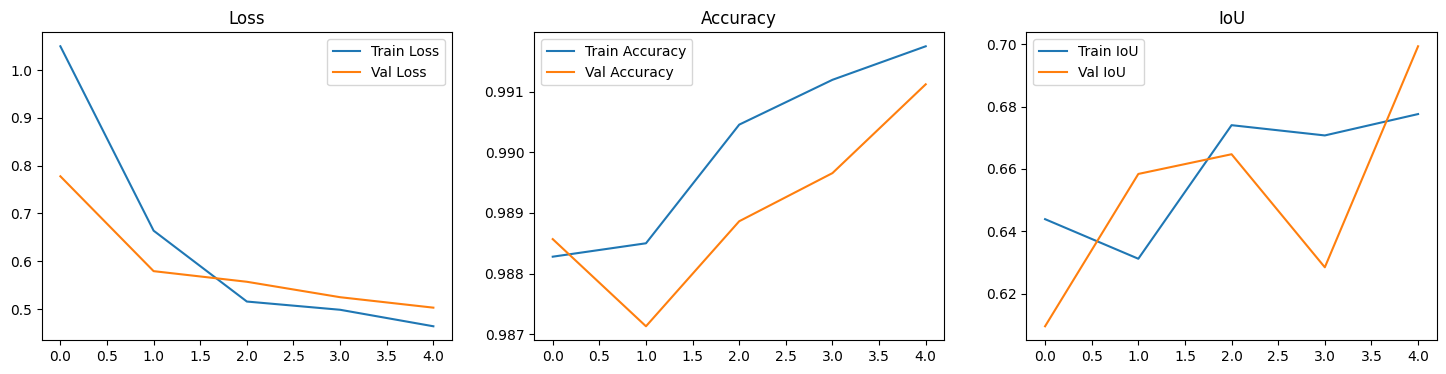

In [11]:
def plot_history(history):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    
    
    axes[0].plot(history.history['loss'], label='Train Loss')
    axes[0].plot(history.history['val_loss'], label='Val Loss')
    axes[0].set_title('Loss')
    axes[0].legend()
    
    axes[1].plot(history.history['accuracy'], label='Train Accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
    axes[1].set_title('Accuracy')
    axes[1].legend()
    
    axes[2].plot(history.history['iou_metric'], label='Train IoU')
    axes[2].plot(history.history['val_iou_metric'], label='Val IoU')
    axes[2].set_title('IoU')
    axes[2].legend()
    
    plt.show()

plot_history(history)

### 5.2 Visualizing Predictions on Test Data

We display 10 test images along with:
- The ground truth masks
- The raw predictions from the model
- The post-processed masks after applying dynamic thresholding and morphological filtering

This helps us visually assess the model's performance.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


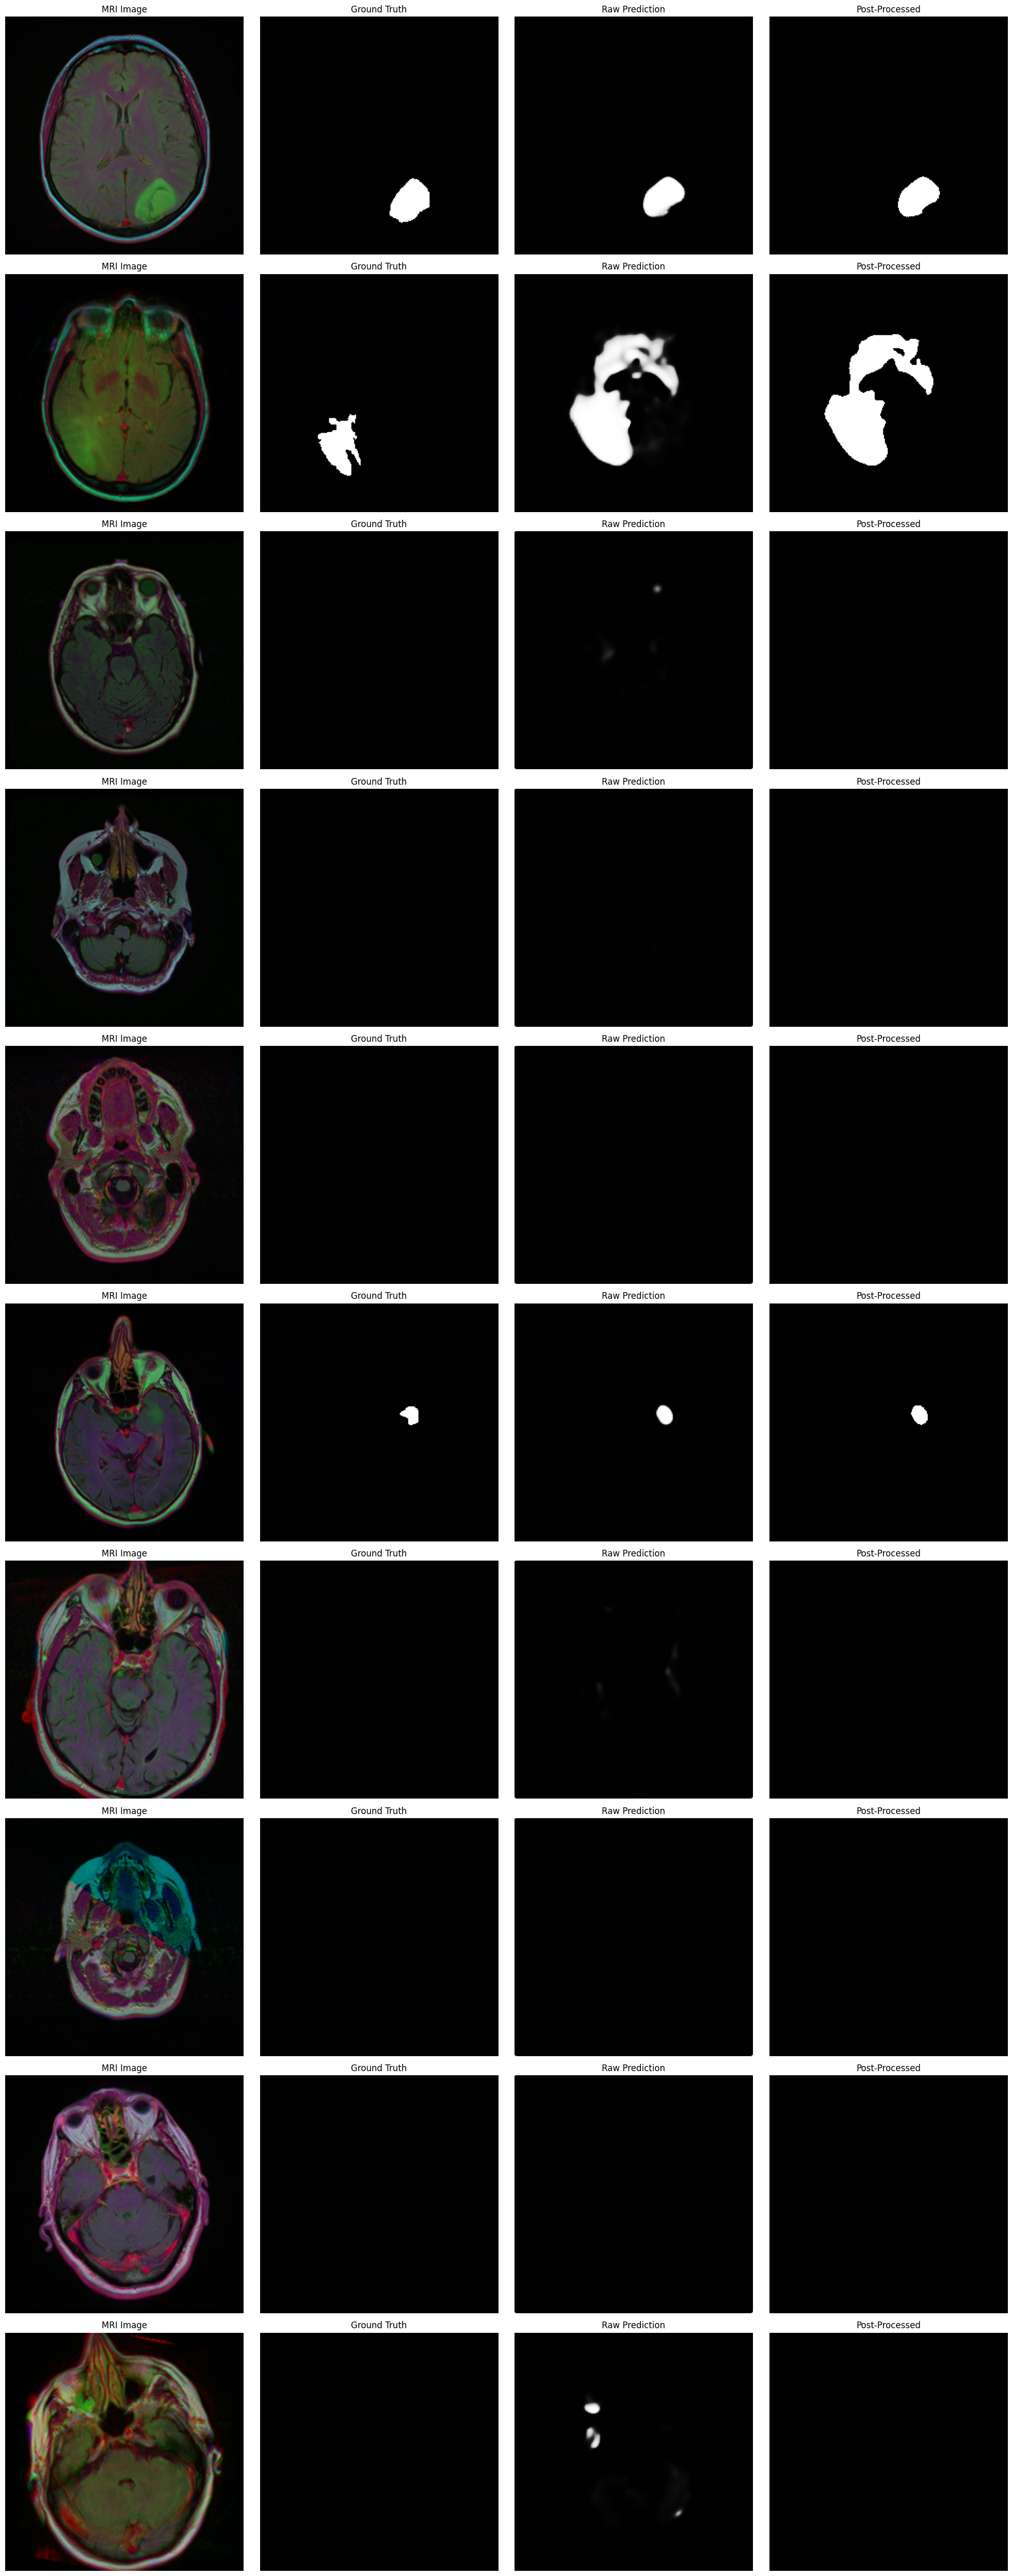

In [20]:
def show_results(num_samples=10):
    fig, ax = plt.subplots(num_samples, 4, figsize=(20, 5*num_samples))
    for i in range(num_samples):
        img = X_test[i]
        mask_true = y_test[i].squeeze()
        mask_pred = seg_model.predict(np.expand_dims(img, axis=0))[0]
        mask_post = post_process_mask(mask_pred)
        
        ax[i,0].imshow(img)
        ax[i,0].set_title('MRI Image')
        ax[i,0].axis('off')
        
        ax[i,1].imshow(mask_true, cmap='gray')
        ax[i,1].set_title('Ground Truth')
        ax[i,1].axis('off')
        
        ax[i,2].imshow(mask_pred.squeeze(), cmap='gray')
        ax[i,2].set_title('Raw Prediction')
        ax[i,2].axis('off')
        
        ax[i,3].imshow(mask_post, cmap='gray')
        ax[i,3].set_title('Post-Processed')
        ax[i,3].axis('off')
    plt.tight_layout()
    plt.show()

show_results(num_samples=10)

## 6. Discussion and Conclusion

- **Model Performance:**  
  The training history plots (loss, accuracy, IoU) provide insights into the model's learning process. While a baseline U-Net is implemented, further hyperparameter tuning or architectural modifications (such as attention modules) could potentially improve performance.

- **Post-Processing:**  
  Dynamic thresholding using Otsu’s method adapts to the individual prediction's intensity distribution. Coupled with morphological filtering, it effectively reduces false positives.

- **Comparison with Literature:**  
  In a formal report, these results would be compared with those from the provided paper, discussing any discrepancies and highlighting areas for further improvement.

- **Future Work:**  
  Bonus challenges include exploring different U-Net variations or incorporating advanced techniques to further enhance segmentation performance.

---

## 7. References
- [LGG Segmentation Dataset on Kaggle](https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation/data)
- [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/pdf/1505.04597)
- [Project Description PDF](https://arxiv.org/pdf/2210.13336)